In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/customer_transactions.csv')

df.head(10)

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand,lifestage,premium_customer
0,2018-10-17,1,1000,1,5,2,6.0,natural chip compny seasalt 175 g,175,Natural Chip Company,YOUNG SINGLES/COUPLES,Premium
1,2019-05-14,1,1307,348,66,3,6.3,ccs nacho cheese 175 g,175,CCs,MIDAGE SINGLES/COUPLES,Budget
2,2019-05-20,1,1343,383,61,2,2.9,smiths crinkle cut chips chicken 170 g,170,Smith's,MIDAGE SINGLES/COUPLES,Budget
3,2018-08-17,2,2373,974,69,5,15.0,smiths chip thinly s cream onion 175 g,175,Smith's,MIDAGE SINGLES/COUPLES,Budget
4,2018-08-18,2,2426,1038,108,3,13.8,kettle tortilla chpshny jlpno chili 150 g,150,Kettle,MIDAGE SINGLES/COUPLES,Budget
5,2019-05-16,4,4149,3333,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget
6,2019-05-16,4,4196,3539,24,1,3.6,grain waves sweet chilli 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
7,2018-08-20,5,5026,4525,42,1,3.9,doritos corn chip mexican jalapeno 150 g,150,Doritos,MIDAGE SINGLES/COUPLES,Budget
8,2018-08-18,7,7150,6900,52,2,7.2,grain waves sour cream chives 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
9,2019-05-17,7,7215,7176,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget


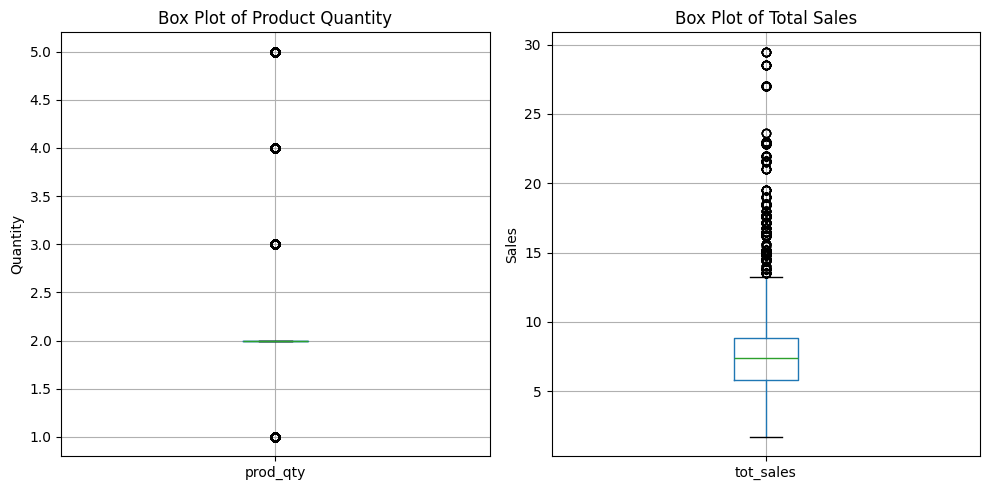

In [2]:
# get a grasp of the distribution of prod_qty and tot_sales using box plots

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

df.boxplot(column="prod_qty", ax=axes[0])
axes[0].set_title("Box Plot of Product Quantity")
axes[0].set_ylabel("Quantity")

df.boxplot(column="tot_sales", ax=axes[1])
axes[1].set_title("Box Plot of Total Sales")
axes[1].set_ylabel("Sales")

plt.tight_layout()
plt.show()

**Product Quantity**
- the usual customer would purchase 2 units </br>
    *quartiles and median appear to converge at 2 units*
- The outliers at 1, 3, 4, and 5 units are not necessarily unusual purchasing behaviors. </br>
    *They simply fall outside the very narrow interquartile range*

**Total Sales** <br>
 - Most txns are concentrated between 5.8 and 8.8 <br>
 - Median of approx 7.4 <br>
 - numerous upper-end outliers, stretching to nearly 30 <br>
 *The longer upper tail suggests that a relatively small number of transactions generate considerably higher sales than typical purchases.*

In [3]:
import pandas as pd


def build_sales_pivot(df, row_col="premium_customer", col_col="lifestage",
                      value_col="tot_sales", as_percent=True):
    """Plain pivot of value_col by row_col x col_col, with Grand Totals.

    as_percent=True  -> each cell is its share of overall sales (%)
    as_percent=False -> raw summed sales
    Returns (numeric_pivot, formatted_pivot).
    """
    pivot = df.pivot_table(index=row_col, columns=col_col, values=value_col,
                           aggfunc="sum", fill_value=0,
                           margins=True, margins_name="Grand Total")

    if as_percent:
        pivot = pivot / pivot.loc["Grand Total", "Grand Total"] * 100

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the original pivot
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    fmt = (lambda v: f"{v:.2f}%") if as_percent else (lambda v: f"{v:,.2f}")
    formatted = pivot.apply(lambda col: col.map(fmt))
    return pivot, formatted



pivot, pivot_fmt = build_sales_pivot(df)
display(pivot_fmt)    

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,1.84%,1.14%,8.68%,7.08%,5.87%,7.18%,3.16%,34.96%
Mainstream,4.70%,0.89%,5.34%,6.90%,8.05%,4.78%,8.19%,38.84%
Premium,3.02%,0.60%,4.17%,6.85%,5.06%,4.35%,2.16%,26.20%
Grand Total,9.56%,2.63%,18.19%,20.83%,18.98%,16.31%,13.51%,100.00%


- Older Singles/Couples account for 20.83% of sales, the highest across all life stages on top of being the most consistent across three pricing levels [avg: 6.94%]
- Both budget Older [8.68%] and Young Families [7.18%] perform better than the Mainstream and Premium counterparts from their life stage 
- The older cohort [retirees], [older_families], and [older_s/c] account for [58%] of all sales, currently the highest average [19.33%perLifestage].
- Mainstream Young S/C account for the second highest individual cohort sales at [8.19%]

*premium members account for 26.20% of sales, the lowest across three membership pricing tiers*

- does headcount influence sales?
- do the outliers [sales_boxplot] produce disproportionate sales?

In [4]:

def build_customer_pivot(df, row_col="premium_customer", col_col="lifestage",
                         customer_col="lylty_card_nbr", as_percent=True):
    #Plain pivot of unique customers by row_col x col_col, with Grand Totals.
    
    # nunique inside margins also gives true unique counts for the totals
    pivot = df.pivot_table(index=row_col, columns=col_col, values=customer_col,
                           aggfunc="nunique", fill_value=0,
                           margins=True, margins_name="Grand Total")

    if as_percent:
        pivot = pivot / pivot.loc["Grand Total", "Grand Total"] * 100

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the original pivot
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    fmt = (lambda v: f"{v:.2f}%") if as_percent else (lambda v: f"{int(v):,}")
    formatted = pivot.apply(lambda col: col.map(fmt))
    return pivot, formatted


pivot, pivot_fmt = build_customer_pivot(df)
display(pivot_fmt)                   

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,2.07%,1.53%,6.47%,6.80%,6.15%,5.55%,5.10%,33.66%
Mainstream,4.63%,1.16%,3.91%,6.82%,8.91%,3.77%,11.11%,40.31%
Premium,3.33%,0.81%,3.13%,6.57%,5.35%,3.37%,3.48%,26.03%
Grand Total,10.02%,3.50%,13.51%,20.19%,20.41%,12.69%,19.69%,100.00%


*numbers are similar to the total sales pivot chart, let's compare it*

In [5]:
def build_sales_vs_customers(df, group_col="lifestage", value_col="tot_sales",
                             customer_col="lylty_card_nbr"):
    """Plain table by group_col: sales %, customers %, and the % differential.

    d_Sales      = share of total sales (%)
    d_Customers  = share of total unique customers (%)
    Difference   = d_Sales - d_Customers (percentage points)
    A Grand Total row tallies each column.
    Returns (numeric_table, formatted_table).
    """
    sales = df.groupby(group_col)[value_col].sum()
    customers = df.groupby(group_col)[customer_col].nunique()

    table = pd.DataFrame({
        "d_Sales": sales / sales.sum() * 100,
        "d_Customers": customers / customers.sum() * 100,
    })
    table["Difference"] = table["d_Sales"] - table["d_Customers"]

    # Display labels, then tally the Grand Total row
    table.index = [str(i).upper() for i in table.index]
    table.index.name = group_col.capitalize()
    table.loc["Grand Total"] = table.sum()

    formatted = table.apply(lambda col: col.map(lambda v: f"{round(v, 2) + 0.0:.2f}%"))
    return table, formatted



table, table_fmt = build_sales_vs_customers(df)
display(table_fmt)                 

,d_Sales,d_Customers,Difference
Lifestage,,,
MIDAGE SINGLES/COUPLES,9.56%,10.02%,-0.46%
NEW FAMILIES,2.63%,3.50%,-0.87%
OLDER FAMILIES,18.19%,13.51%,4.68%
OLDER SINGLES/COUPLES,20.83%,20.19%,0.64%
RETIREES,18.98%,20.41%,-1.43%
YOUNG FAMILIES,16.31%,12.69%,3.62%
YOUNG SINGLES/COUPLES,13.51%,19.69%,-6.18%
Grand Total,100.00%,100.00%,0.00%


*in general, sales is almost 1:1 with population*
    - consumers spend a similar amount on average

**Older Families** and **Young Families** produce slightly greater sales compared to their headcount
    - this makes sense, they are purchasing a family's worth of chips

**Young Singles/Couples** produce sales that are -6.18% less than their headcount
    - sales is only 68.6% of their headcount, low when compared to counterparts with <1% differentials

In [6]:
# zoom into young s/c to investigate the low sales% vs customers% and see if the difference is driven by one tier

def build_segment_by_tier(df, segment="YOUNG SINGLES/COUPLES",
                          group_col="lifestage", tier_col="premium_customer",
                          value_col="tot_sales", customer_col="lylty_card_nbr",
                          within_segment=False):
    """Zoom into one lifestage and break it down by membership tier.

    d_Sales      = tier's share of total sales (%)
    d_Customers  = tier's share of total unique customers (%)
    Difference   = d_Sales - d_Customers (percentage points)

    Denominators are the overall totals (same basis as build_sales_vs_customers),
    so the Grand Total row matches the segment's row in that table.
    Set within_segment=True to use the segment's own totals instead
    (each tier's share of the segment).
    Returns (numeric_table, formatted_table).
    """
    # Denominators on the same basis as the original table
    total_sales = df[value_col].sum()
    total_customers = df.groupby(group_col)[customer_col].nunique().sum()

    # Case-insensitive match so label formatting doesn't matter
    mask = df[group_col].astype(str).str.upper().str.strip() == segment.upper()
    seg = df[mask]
    if seg.empty:
        raise ValueError(f"No rows found for {group_col} = '{segment}'. "
                         f"Available: {sorted(df[group_col].astype(str).unique())}")

    sales = seg.groupby(tier_col)[value_col].sum()
    customers = seg.groupby(tier_col)[customer_col].nunique()

    if within_segment:
        total_sales, total_customers = sales.sum(), customers.sum()

    table = pd.DataFrame({
        "d_Sales": sales / total_sales * 100,
        "d_Customers": customers / total_customers * 100,
    })
    table["Difference"] = table["d_Sales"] - table["d_Customers"]

    # Display labels, then tally the Grand Total row
    table.index = [str(i).upper() for i in table.index]
    table.index.name = tier_col.replace("_", " ").title()
    table.loc["Grand Total"] = table.sum()

    formatted = table.apply(lambda col: col.map(lambda v: f"{round(v, 2) + 0.0:.2f}%"))
    return table, formatted


# Share of overall sales/customers (ties back to the first table)
seg_table, seg_fmt = build_segment_by_tier(df)
display(seg_fmt)

# Optional: each tier's share *within* Young Singles/Couples
seg_table_in, seg_fmt_in = build_segment_by_tier(df, within_segment=True)
display(seg_fmt_in)

,d_Sales,d_Customers,Difference
Premium Customer,,,
BUDGET,3.16%,5.10%,-1.94%
MAINSTREAM,8.19%,11.11%,-2.92%
PREMIUM,2.16%,3.48%,-1.31%
Grand Total,13.51%,19.69%,-6.18%


,d_Sales,d_Customers,Difference
Premium Customer,,,
BUDGET,23.38%,25.92%,-2.53%
MAINSTREAM,60.61%,56.43%,4.18%
PREMIUM,16.00%,17.65%,-1.65%
Grand Total,100.00%,100.00%,0.00%


young s/c is generally a low-sales cohort, with all 3 membership tiers netting sales % below their customer %. <br>

the disparity in sales made the second table trickier to interpret; let's break it down

- Mainstream tier is the largest population
- also the standout tier in sales %, accounting for 60.6% of this life stage's total sales. 

Taking into perpective how their shares make up the totals of the entire cohort, *Mainstream Young S/C is the sole tier with a net positive (+4.18%) in sales% vs customer% in its own life stage*

- Mainstream Young S/C accounts for 8.19% of all sales, but make up 60.6% of this cohort's sales. 
- This is larger than their customers %, at only 56.4% of the lifestage despite having a raw 11.11% global customer share.



In [7]:
# average spend per customer by lifestage and membership tier

def build_avg_spend_pivot(df, row_col="premium_customer", col_col="lifestage",
                          value_col="tot_sales", customer_col="lylty_card_nbr"):
    
    """Plain pivot of average spend per customer by row_col x col_col."""
    
    total_sales = df.pivot_table(index=row_col, columns=col_col, values=value_col,
                                 aggfunc="sum", fill_value=0,
                                 margins=True, margins_name="Grand Total")
    customers = df.pivot_table(index=row_col, columns=col_col, values=customer_col,
                               aggfunc="nunique", fill_value=0,
                               margins=True, margins_name="Grand Total")

    pivot = total_sales / customers  # empty segments become NaN

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the other pivots
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    formatted = pivot.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:,.2f}"))
    return pivot, formatted


pivot, pivot_fmt = build_avg_spend_pivot(df)
display(pivot_fmt)

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,22.55,18.91,33.89,26.30,24.13,32.69,15.64,26.24
Mainstream,25.64,19.25,34.53,25.56,22.80,32.02,18.62,24.34
Premium,22.92,18.66,33.60,26.32,23.90,32.61,15.71,25.42
Grand Total,24.10,18.96,34.01,26.06,23.49,32.47,17.33,25.26


*spending amount is similar across affluence levels, with the difference hovering only at around 1-2%*
 - **lifestage is a better indicator of spending average**

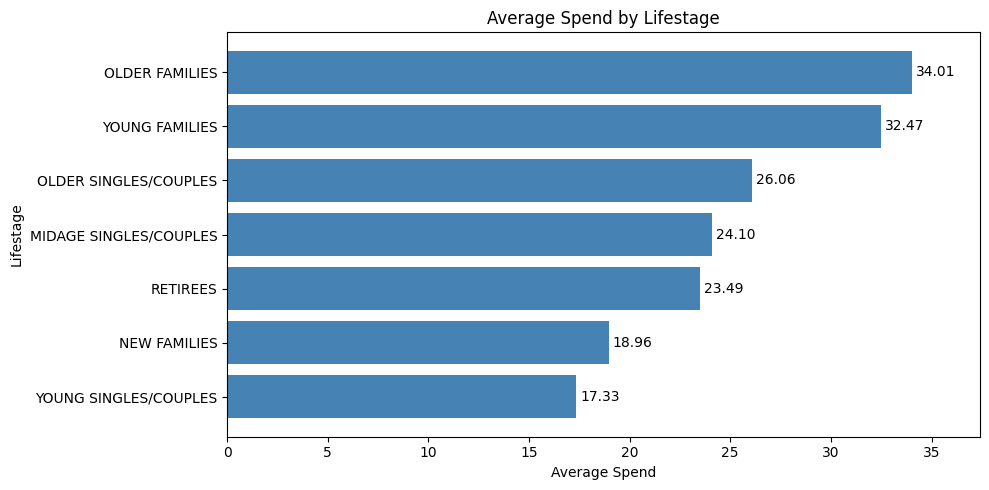

In [8]:
# Average total spend per customer by lifestage across the analysis period.
customer_spend = df.groupby(["lifestage", "lylty_card_nbr"], as_index=False)["tot_sales"].sum()
lifestage_spend = customer_spend.groupby("lifestage")["tot_sales"].mean().sort_values(ascending=False)


fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(lifestage_spend.index, lifestage_spend.values, color="steelblue")
ax.invert_yaxis()  # Highest average spend at the top

ax.set_title("Average Spend by Lifestage")
ax.set_xlabel("Average Spend")
ax.set_ylabel("Lifestage")

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)

ax.margins(x=0.1)
plt.tight_layout()
plt.show()

*On average, families spend more per transaction compared to other lifestages*

*Retirees, as well as Older & Midage S/C sit at the middle in terms of avg spend*

*Younger, and non-family segments spend the lowest on average*

 - these points just make sense, given each lifestage's practical priorities

 *from these generalized data, let's dive deeper on the cohorts spending habits*

In [9]:
# Average transactions per customer by lifestage and membership tier

def build_avg_txn_pivot(df, row_col="premium_customer", col_col="lifestage",
                        txn_col="txn_id", customer_col="lylty_card_nbr",
                        unique_txns=True):
    
    txn_agg = "nunique" if unique_txns else "count"
    txns = df.pivot_table(index=row_col, columns=col_col, values=txn_col,
                          aggfunc=txn_agg, fill_value=0,
                          margins=True, margins_name="Grand Total")
    customers = df.pivot_table(index=row_col, columns=col_col, values=customer_col,
                               aggfunc="nunique", fill_value=0,
                               margins=True, margins_name="Grand Total")

    pivot = txns / customers  # empty segments become NaN

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the other pivots
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    formatted = pivot.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:,.2f}"))
    return pivot, formatted


pivot, pivot_fmt = build_avg_txn_pivot(df)
display(pivot_fmt)

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,3.14,2.58,4.60,3.51,3.22,4.43,2.33,3.57
Mainstream,3.33,2.62,4.69,3.47,3.12,4.39,2.45,3.28
Premium,3.18,2.57,4.59,3.50,3.18,4.43,2.34,3.46
Grand Total,3.24,2.59,4.62,3.49,3.16,4.42,2.40,3.43


In [10]:
# Average product quantity per transaction by lifestage and membership tier

def build_avg_qty_pivot(df, row_col="premium_customer", col_col="lifestage",
                        qty_col="prod_qty"):
    """Plain pivot of average prod_qty per transaction row by row_col x col_col.

    Every row in df is treated as one transaction, so each cell is the plain
    mean of prod_qty over all rows in that segment. Grand Totals are the mean
    over all underlying rows for that row/column/overall (not an average of
    the cell averages).
    Returns (numeric_pivot, formatted_pivot).
    """
    pivot = df.pivot_table(index=row_col, columns=col_col, values=qty_col,
                           aggfunc="mean",
                           margins=True, margins_name="Grand Total")

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the other pivots
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    formatted = pivot.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:,.2f}"))
    return pivot, formatted


pivot, pivot_fmt = build_avg_qty_pivot(df)
display(pivot_fmt)

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,1.89,1.86,1.95,1.91,1.89,1.94,1.81,1.91
Mainstream,1.91,1.86,1.95,1.91,1.89,1.94,1.85,1.90
Premium,1.89,1.86,1.95,1.91,1.90,1.94,1.81,1.91
Grand Total,1.90,1.86,1.95,1.91,1.89,1.94,1.83,1.91


*the raw averages seem confusing on its own, with consistent values of <2 across the board*

- let's investigate this further with a visualization and a bunch of stats

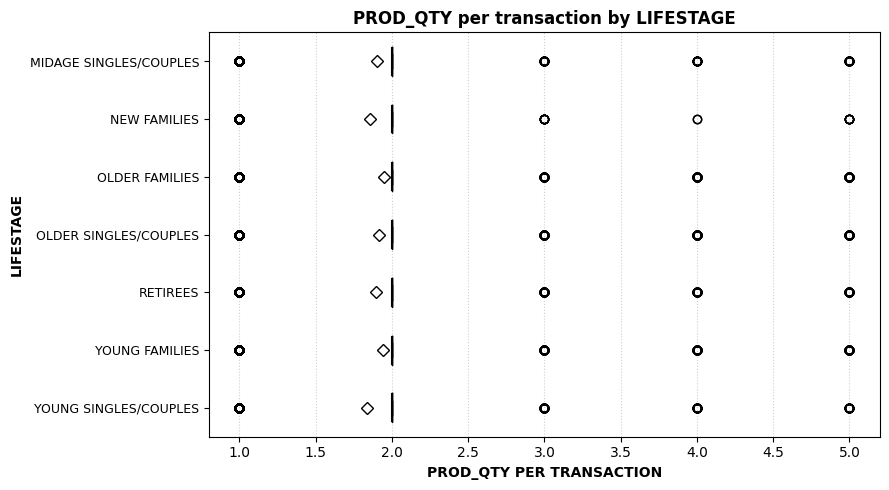

,count,mean,std,min,25%,50%,75%,max
lifestage,,,,,,,,
MIDAGE SINGLES/COUPLES,23273.0,1.901689,0.349278,1.0,2.0,2.0,2.0,5.0
NEW FAMILIES,6466.0,1.858027,0.373041,1.0,2.0,2.0,2.0,5.0
OLDER FAMILIES,44865.0,1.946573,0.300415,1.0,2.0,2.0,2.0,5.0
OLDER SINGLES/COUPLES,50488.0,1.913425,0.330915,1.0,2.0,2.0,2.0,5.0
RETIREES,46203.0,1.892734,0.352423,1.0,2.0,2.0,2.0,5.0
YOUNG FAMILIES,40219.0,1.940526,0.312030,1.0,2.0,2.0,2.0,5.0
YOUNG SINGLES/COUPLES,33787.0,1.834463,0.402044,1.0,2.0,2.0,2.0,5.0


In [11]:
import matplotlib.pyplot as plt

def plot_qty_boxplots(df, group_col="lifestage", qty_col="prod_qty",
                      save_path="avg_qty_boxplot.png"):
    """Horizontal box plots of prod_qty per transaction row, one box per lifestage.

    Every row in df is treated as one transaction, so each box shows the
    distribution of prod_qty across all rows in that lifestage. The diamond
    marks the mean. Returns the per-lifestage summary statistics.
    """
    groups = sorted(df[group_col].dropna().unique())
    data = [df.loc[df[group_col] == g, qty_col].dropna() for g in groups]

    fig, ax = plt.subplots(figsize=(9, max(5, 0.7 * len(groups))))
    ax.boxplot(data, vert=False, showmeans=True,
               medianprops=dict(color="black", linewidth=1.5),
               meanprops=dict(marker="D", markerfacecolor="white",
                              markeredgecolor="black", markersize=6))

    # Lifestages on the y-axis
    ax.set_yticks(range(1, len(groups) + 1))
    ax.set_yticklabels([str(g).upper() for g in groups], fontsize=9)
    ax.invert_yaxis()  # first group at the top, reading top to bottom

    ax.set_ylabel(group_col.upper(), fontweight="bold")
    ax.set_xlabel(f"{qty_col.upper()} PER TRANSACTION", fontweight="bold")
    ax.set_title(f"{qty_col.upper()} per transaction by {group_col.upper()}",
                 fontsize=12, fontweight="bold")
    ax.xaxis.grid(True, linestyle=":", alpha=0.6)
    ax.set_axisbelow(True)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    return df.groupby(group_col)[qty_col].describe()


summary = plot_qty_boxplots(df)
summary

the usual buyer would pick up 2 units of chips

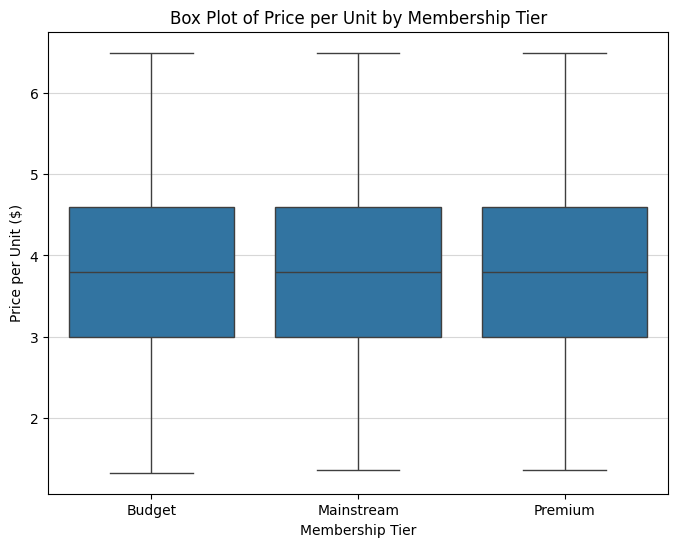

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

df["price_per_unit"] = df["tot_sales"] / df["prod_qty"]

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df,
    x="premium_customer",
    y="price_per_unit",
    order=["Budget", "Mainstream", "Premium"],
)
plt.title("Box Plot of Price per Unit by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Price per Unit ($)")
plt.grid(axis="y", alpha=0.5)
plt.show()

In [13]:
df.groupby("premium_customer")["price_per_unit"].describe()

,count,mean,std,min,25%,50%,75%,max
premium_customer,,,,,,,,
Budget,86191.0,3.809687,1.085007,1.32,3.0,3.8,4.6,6.5
Mainstream,94546.0,3.880352,1.063231,1.35,3.0,3.8,4.6,6.5
Premium,64564.0,3.820023,1.083702,1.35,3.0,3.8,4.6,6.5


$ spend_per_customer remain at around $3.80 across all the membership tiers. 

- The premium tier has identical max purchases at $6.5
- not due to luck; the upper end of the plot also looks uniform

*Lifestage and cohort population are better indicators of spending habits*

In [14]:
# average units per customer by lifestage and membership tier


def build_avg_units_pivot(df, row_col="premium_customer", col_col="lifestage",
                          qty_col="prod_qty", customer_col="lylty_card_nbr"):
  
    units = df.pivot_table(index=row_col, columns=col_col, values=qty_col,
                           aggfunc="sum", fill_value=0,
                           margins=True, margins_name="Grand Total")
    customers = df.pivot_table(index=row_col, columns=col_col, values=customer_col,
                               aggfunc="nunique", fill_value=0,
                               margins=True, margins_name="Grand Total")

    pivot = units / customers  # empty segments become NaN (DIVIDE -> blank)

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the other pivots
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    formatted = pivot.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:,.2f}"))
    return pivot, formatted


pivot, pivot_fmt = build_avg_units_pivot(df)
display(pivot_fmt)

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,5.99,4.80,9.02,6.75,6.13,8.67,4.23,6.87
Mainstream,6.41,4.88,9.23,6.67,5.91,8.58,4.56,6.27
Premium,6.05,4.80,9.02,6.74,6.08,8.66,4.25,6.65
Grand Total,6.20,4.83,9.08,6.72,6.02,8.64,4.42,6.57


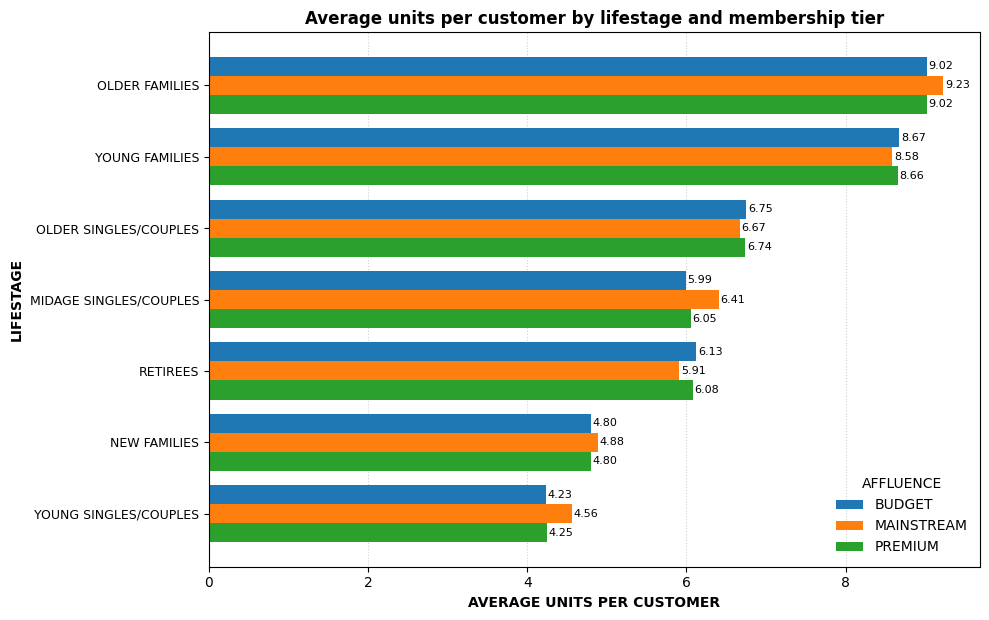

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def plot_avg_units_hbar(pivot, save_path="avg_units_per_customer_hbar.png"):
    """Clustered horizontal bar chart, lifestages sorted by overall average (descending)."""
    # Sort lifestage columns by the Grand Total row, highest first
    if "Grand Total" in pivot.index:
        sort_order = (pivot.loc["Grand Total"]
                           .drop("Grand Total", errors="ignore")
                           .sort_values(ascending=False)
                           .index)
        pivot = pivot[list(sort_order) + (["Grand Total"] if "Grand Total" in pivot.columns else [])]

    # Drop the Grand Total row/column
    data = pivot.drop(index="Grand Total", errors="ignore") \
                .drop(columns="Grand Total", errors="ignore")

    tiers = list(data.index)          # Budget, Mainstream, Premium
    lifestages = list(data.columns)
    y = np.arange(len(lifestages))
    bar_h = 0.8 / len(tiers)

    fig, ax = plt.subplots(figsize=(10, max(5, 0.9 * len(lifestages))))

    for i, tier in enumerate(tiers):
        vals = data.loc[tier].values.astype(float)
        offset = (i - (len(tiers) - 1) / 2) * bar_h
        bars = ax.barh(y + offset, np.nan_to_num(vals), height=bar_h, label=tier.upper())

        # Value labels at the end of each bar (skip empty segments)
        for bar, v in zip(bars, vals):
            if not np.isnan(v):
                ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
                        f"{v:,.2f}", va="center", fontsize=8)

    ax.set_yticks(y)
    ax.set_yticklabels(lifestages, fontsize=9)
    ax.invert_yaxis()  # first lifestage at the top

    ax.set_xlabel("AVERAGE UNITS PER CUSTOMER", fontweight="bold")
    ax.set_ylabel("LIFESTAGE", fontweight="bold")
    ax.set_title("Average units per customer by lifestage and membership tier",
                 fontsize=12, fontweight="bold")
    ax.xaxis.grid(True, linestyle=":", alpha=0.6)
    ax.set_axisbelow(True)
    ax.legend(title="AFFLUENCE", frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


plot_avg_units_hbar(pivot)

*Regardless of age, families pick-up more items on average, compared to other lifestages*
- except for new families <2nd lowest avg chip packets>

*Midage to Older lifestages sit in the middle at an approximate avg of 6 units*
- consists of retirees, midage s/c, and older s/c

*Young s/c account for the lowest avg units at 4.42 across all three membership tiers*
- Mainstream segment with a fractional lead vs other tiers

In [16]:
# average price per unit by lifestage and membership tier


def build_price_per_unit_pivot(df, row_col="premium_customer", col_col="lifestage",
                               sales_col="tot_sales", qty_col="prod_qty"):

   
    sales = df.pivot_table(index=row_col, columns=col_col, values=sales_col,
                           aggfunc="sum", fill_value=0,
                           margins=True, margins_name="Grand Total")
    units = df.pivot_table(index=row_col, columns=col_col, values=qty_col,
                           aggfunc="sum", fill_value=0,
                           margins=True, margins_name="Grand Total")

    pivot = sales / units  # empty segments become NaN (DIVIDE -> blank)

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the other pivots
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    formatted = pivot.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:,.2f}"))
    return pivot, formatted


pivot, pivot_fmt = build_price_per_unit_pivot(df)
display(pivot_fmt)

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,3.76,3.94,3.76,3.90,3.94,3.77,3.69,3.82
Mainstream,4.00,3.94,3.74,3.83,3.86,3.73,4.08,3.88
Premium,3.79,3.89,3.73,3.90,3.93,3.77,3.70,3.83
Grand Total,3.88,3.93,3.74,3.88,3.90,3.76,3.92,3.84


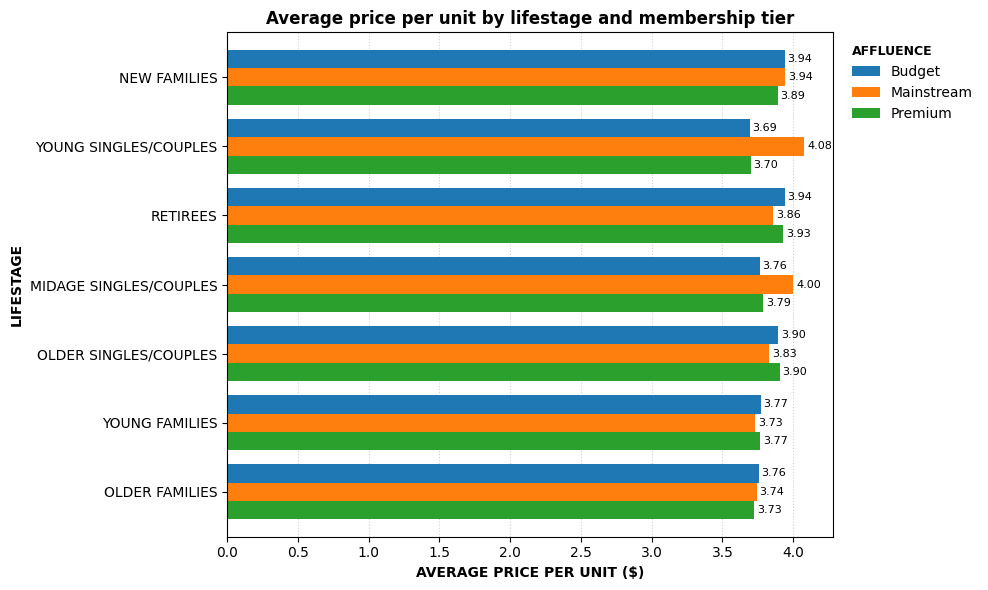

In [17]:
# Sort lifestages by overall price per unit (highest first), then drop Grand Total
order = pivot.loc["Grand Total"].drop("Grand Total").sort_values(ascending=False).index
data = pivot.loc[:, order].drop(index="Grand Total")

# Rows = tiers, columns = lifestages -> transpose so lifestages are the clusters
ax = data.T.plot.barh(figsize=(10, 6), width=0.8)

ax.invert_yaxis()  # highest lifestage on top
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=2, fontsize=8)

ax.set_xlabel("AVERAGE PRICE PER UNIT ($)", fontweight="bold")
ax.set_ylabel("LIFESTAGE", fontweight="bold")
ax.set_title("Average price per unit by lifestage and membership tier", fontweight="bold")
ax.xaxis.grid(True, linestyle=":", alpha=0.6)
ax.set_axisbelow(True)
ax.legend(
    title="AFFLUENCE",
    title_fontproperties={"weight": "bold", "size": 9},
    loc="upper left",
    bbox_to_anchor=(1.01, 1),   # place outside, right of the plot
    frameon=False,
    alignment="left",           # aligns the title with the entries (matplotlib 3.6+)
)

plt.tight_layout()
plt.savefig("price_per_unit_hbar.png", dpi=200, bbox_inches="tight")
plt.show()

*average $_spend per unit is almost uniform at around $3.8*
- $4.08 upper-limit
- $3.70 lowest avg

sales % is still the largest factor for prioritization <br>

- Older Singles/Couples are the most consistent and safe cohort to target, with healthy sales markers throughout. <br>
- Mainstream Retirees and Budget Older Families account for substantial sales, and are 3-4% greater than other membership tiers from the same lifestages. <br>
- Budget Young Families and Mainstream Young S/C show promising sales percent, these are the CLV picks <br>

--> New Families have the smallest population (and sales %) by far. Capitalizing on the existing headcount and looking into member acquisition could pose positive CLV given that family-oriented cohorts are the best-performing ones, regardless of age. 

In [18]:
# CHECK THE SIGNIFICANCE OF THE DIFFERENCE IN PRICE PER UNIT BETWEEN MAINSTREAM AND BUDGET YOUNG S/C
from scipy import stats

# --- 1. Select the two segments (case-insensitive match on lifestage) ---
young = df[df["lifestage"].str.upper().str.contains("YOUNG SINGLES")].copy()
young["price_per_unit"] = young["tot_sales"] / young["prod_qty"]

main = young[young["premium_customer"] == "Mainstream"]
budget = young[young["premium_customer"] == "Budget"]

def compare(a, b, label):
    """Welch t-test + effect size + 95% CI + Mann-Whitney robustness check."""
    t, p = stats.ttest_ind(a, b, equal_var=False)
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
    # Welch-Satterthwaite degrees of freedom
    dof = se**4 / ((a.var(ddof=1)/len(a))**2/(len(a)-1) + (b.var(ddof=1)/len(b))**2/(len(b)-1))
    ci = (diff - stats.t.ppf(0.975, dof)*se, diff + stats.t.ppf(0.975, dof)*se)
    pooled_sd = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    u, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")

    print(f"--- {label} ---")
    print(f"n (Mainstream, Budget): {len(a):,}, {len(b):,}")
    print(f"Mean (Mainstream, Budget): {a.mean():.3f}, {b.mean():.3f}")
    print(f"Mean diff: {diff:.3f}  95% CI: ({ci[0]:.3f}, {ci[1]:.3f})")
    print(f"Welch t = {t:.2f}, p = {p:.4g}")
    print(f"Cohen's d = {diff/pooled_sd:.3f}")
    print(f"Mann-Whitney p = {p_mw:.4g}\n")

# --- 2. Transaction-level test ---
compare(main["price_per_unit"], budget["price_per_unit"], "Transaction level")

# --- 3. Customer-level test (respects independence) ---
# Price per unit per customer = total sales / total units across their transactions
def per_customer(seg):
    g = seg.groupby("lylty_card_nbr").agg(sales=("tot_sales", "sum"),
                                          units=("prod_qty", "sum"))
    return g["sales"] / g["units"]

compare(per_customer(main), per_customer(budget), "Customer level")

--- Transaction level ---
n (Mainstream, Budget): 19,472, 8,502
Mean (Mainstream, Budget): 4.071, 3.666
Mean diff: 0.405  95% CI: (0.378, 0.432)
Welch t = 29.18, p = 3.956e-182
Cohen's d = 0.394
Mann-Whitney p = 1.676e-196

--- Customer level ---
n (Mainstream, Budget): 7,908, 3,632
Mean (Mainstream, Budget): 4.133, 3.626
Mean diff: 0.507  95% CI: (0.473, 0.542)
Welch t = 28.69, p = 1.585e-169
Cohen's d = 0.624
Mann-Whitney p = 3.053e-177



Mainstream Young Singles/Couples pay a statistically significant premium per unit over their Budget counterparts, about $0.51 more at the customer level (95% CI: $0.47 to $0.54, roughly 14% higher), a medium-sized effect (Cohen's d = 0.62) confirmed by both parametric and non-parametric tests.


- Caveat: this shows that Mainstream customers pay more per unit, not why. The cause could be product mix (premium brands or different pack sizes) rather than price sensitivity

In [19]:
# create variable for the Mainstream vs Budget difference in price per unit for Young S/C

segment_main_youngsc = df[
    (df["lifestage"] == "YOUNG SINGLES/COUPLES") & (df["premium_customer"] == "Mainstream")
]
comparison_main_youngsc = df[
    (df["lifestage"] == "YOUNG SINGLES/COUPLES") & (df["premium_customer"] == "Budget")
]

In [20]:
def classify_affinity(score):
    """Tiers are mirrored on the ratio scale (1.20 <-> 1/1.20), so over- and
    under-indexing are held to the same standard."""
    if pd.isna(score):
        return "No Data"
    if score >= 1.20:        return "Very High"      # 20%+ above
    elif score >= 1.10:      return "High"           # 10-20% above
    elif score >= 1.05:      return "Moderate High"  # 5-10% above
    elif score >= 1 / 1.05:  return "Neutral"        # roughly 0.95 to 1.05
    elif score >= 1 / 1.10:  return "Moderate Low"   # roughly 0.91 to 0.95
    elif score >= 1 / 1.20:  return "Low"            # roughly 0.83 to 0.91
    else:                    return "Very Low"       # below roughly 0.83


def affinity_table(segment, other, item_col="brand", value_col="prod_qty", z=1.96):
    """Affinity per item with a significance flag.

    significant = True when the score differs from 1 by more than sampling
    noise would explain (approximate 95% test on the log ratio). Rows are
    treated as independent, so this slightly overstates confidence because
    units from the same customer are correlated.
    """
    a = segment.groupby(item_col)[value_col].sum()
    b = other.groupby(item_col)[value_col].sum()
    A, B = a.sum(), b.sum()

    t = pd.DataFrame({"seg_units": a, "other_units": b}).fillna(0)
    with np.errstate(divide="ignore", invalid="ignore"):
        t["affinity"] = (t["seg_units"] / A) / (t["other_units"] / B)
        se = np.sqrt(1 / t["seg_units"] - 1 / A + 1 / t["other_units"] - 1 / B)
        t["significant"] = np.abs(np.log(t["affinity"])) > z * se
    t["tier"] = t["affinity"].map(classify_affinity)
    return t.sort_values("affinity", ascending=False)

brand_affinity = affinity_table(segment_main_youngsc, comparison_main_youngsc, item_col="brand")

display(brand_affinity)

,seg_units,other_units,affinity,significant,tier
brand,,,,,
Tostitos,1645,503,1.393410,True,Very High
Kettle,7172,2255,1.355111,True,Very High
Cobs,1617,528,1.304840,True,Very High
Doritos,4447,1453,1.304015,True,Very High
Twisties,1673,556,1.282042,True,Very High
Tyrrells,1143,386,1.261653,True,Very High
Pringles,4326,1527,1.207059,True,Very High
Infuzions,2343,837,1.192691,True,High
Grain Waves,1185,446,1.132047,True,High


In [21]:
# --- 1. Concentration: how selective is each tier? ---
seg_share = brand_affinity["seg_units"] / brand_affinity["seg_units"].sum()
oth_share = brand_affinity["other_units"] / brand_affinity["other_units"].sum()

def concentration(share):
    s = share.sort_values(ascending=False)
    return {
        "top3": s.head(3).sum(),
        "top5": s.head(5).sum(),
        "HHI": (share**2).sum() * 10000,
        "effective_brands": 1 / (share**2).sum(),
        "brands_for_80pct": (s.cumsum() < 0.8).sum() + 1,
    }

display(pd.DataFrame({"Mainstream": concentration(seg_share),
                      "Budget": concentration(oth_share)}).round(3))

# --- 2. Brand price per unit, using the same two segments as the affinity table ---
both = pd.concat([segment_main_youngsc, comparison_main_youngsc])
brand_ppu = (both.groupby("brand")
                 .agg(sales=("tot_sales", "sum"), units=("prod_qty", "sum")))
brand_ppu = brand_ppu["sales"] / brand_ppu["units"]

brand_affinity["brand_ppu"] = brand_ppu

# --- 3. Does affinity track price? ---
print(brand_affinity[["affinity", "brand_ppu"]].corr(method="spearman").round(3))
display(brand_affinity[["seg_units", "other_units", "affinity", "brand_ppu", "tier"]]
        .sort_values("brand_ppu", ascending=False).round(3))

,Mainstream,Budget
top3,0.442,0.374
top5,0.600,0.546
HHI,973.780,806.550
effective_brands,10.269,12.398
brands_for_80pct,10.000,11.000


           affinity  brand_ppu
affinity      1.000      0.867
brand_ppu     0.867      1.000


,seg_units,other_units,affinity,brand_ppu,tier
brand,,,,,
Kettle,7172,2255,1.355,4.936,Very High
Cheezels,651,282,0.984,4.782,Neutral
Doritos,4447,1453,1.304,4.704,Very High
Twisties,1673,556,1.282,4.502,Very High
Tostitos,1645,503,1.393,4.400,Very High
Tyrrells,1143,386,1.262,4.200,Very High
Smith's,3361,1973,0.726,4.064,Very Low
Cobs,1617,528,1.305,3.800,Very High
Pringles,4326,1527,1.207,3.700,Very High


Mainstream Young Singles/Couples buy a measurably different brand mix from their Budget counterparts, one that is more concentrated (top 3 brands account for 44% of units vs. 37%; effective brands 10.3 vs. 12.4) and strongly tilted toward higher-priced brands (Spearman ρ = 0.87 between brand affinity and brand price per unit). This pattern supports product mix as a primary driver of the $0.51 per-unit price premium, rather than Mainstream customers paying more for the same products. The next step is to confirm this by comparing price per unit within the same brand and pack size.

In [22]:
seg = df[df["lifestage"].str.upper().str.contains("YOUNG SINGLES")
         & df["premium_customer"].isin(["Mainstream", "Budget"])].copy()

# Gap within each brand x pack size (same product, different tier)
cell = (seg.groupby(["brand", "net_weight", "premium_customer"])
           .agg(sales=("tot_sales", "sum"), units=("prod_qty", "sum")))
cell["ppu"] = cell["sales"] / cell["units"]
within = cell["ppu"].unstack("premium_customer").dropna()
within["gap"] = within["Mainstream"] - within["Budget"]

print(f"Median within-product gap: {within['gap'].median():.3f}")
print(f"Share of products where Mainstream pays more: {(within['gap'] > 0).mean():.1%}")

Median within-product gap: 0.000
Share of products where Mainstream pays more: 5.3%


In [ ]:
# Create a Brand + Pack identifier

df["brand_pack"] = (
    df["brand"] + " " + df["net_weight"].astype(int).astype(str) + "g"
)

# repeat the variables for the brand_pack level affinity table

segment_main_youngsc = df[
    (df["lifestage"] == "YOUNG SINGLES/COUPLES") & (df["premium_customer"] == "Mainstream")
]
comparison_main_youngsc = df[
    (df["lifestage"] == "YOUNG SINGLES/COUPLES") & (df["premium_customer"] == "Budget")
]

In [26]:
# Brand + Pack affinity (Mainstream Young Singles/Couples)
brand_pack_affinity = pd.merge(
    (
        segment_main_youngsc.groupby("brand_pack")["prod_qty"].sum()
        / segment_main_youngsc["prod_qty"].sum()
    ).rename("target_segment"),
    (
        comparison_main_youngsc.groupby("brand_pack")["prod_qty"].sum()
        / comparison_main_youngsc["prod_qty"].sum()
    ).rename("other"),
    on="brand_pack"
)

brand_pack_affinity["affinity_to_brand_pack"] = (
    brand_pack_affinity["target_segment"]
    / brand_pack_affinity["other"]
)

brand_pack_affinity = (
    brand_pack_affinity
    .sort_values("affinity_to_brand_pack", ascending=False)
    .reset_index()
)

display(brand_pack_affinity)

,brand_pack,target_segment,other,affinity_to_brand_pack
0,Smith's 380g,0.016512,0.009949,1.659724
1,Cheezels 330g,0.015016,0.009949,1.509346
2,Smith's 330g,0.031002,0.021523,1.440400
3,Twisties 270g,0.031943,0.022563,1.415731
4,Tostitos 175g,0.045574,0.032707,1.393410
5,Kettle 175g,0.091647,0.065869,1.391352
6,Doritos 380g,0.015764,0.011769,1.339414
7,Kettle 150g,0.092229,0.069055,1.335581
8,Infuzions 110g,0.061865,0.046492,1.330650
9,Doritos 170g,0.062945,0.047532,1.324256


Mainstream Young Singles/Couples differ from Budget in both brand and pack choice. They over-index on every pack of 250g or more (about 14% of their units vs. 10% for Budget) and on Kettle, Doritos, Tostitos, Tyrrells, Cobs and Pringles at every size, while Budget favors value brands such as Woolworths, CCs and Sunbites across all packs. <br>

Pack size also reverses results within a brand: Smith's, Cheezels and Infuzions are strongly favored by Mainstream in large packs (affinity 1.3 to 1.7) but under-indexed in small ones (0.4 to 0.5), a split that brand-level affinity masked.

 - Because price per unit is measured per pack, the $0.51 premium likely reflects larger packs as well as higher-priced brands, so the next step is to retest the gap on price per 100g.

In [27]:
def per_customer_100g(d):
    g = (d.assign(grams=d["prod_qty"] * d["net_weight"])   # assumes net_weight is numeric grams
           .groupby("lylty_card_nbr")[["tot_sales", "grams"]].sum())
    return g["tot_sales"] / g["grams"] * 100

compare(per_customer_100g(segment_main_youngsc),
        per_customer_100g(comparison_main_youngsc),
        "Customer level, price per 100g")

--- Customer level, price per 100g ---
n (Mainstream, Budget): 7,908, 3,632
Mean (Mainstream, Budget): 2.405, 2.162
Mean diff: 0.243  95% CI: (0.221, 0.266)
Welch t = 21.15, p = 5.16e-96
Cohen's d = 0.442
Mann-Whitney p = 4.371e-103



Mainstream Young Singles/Couples pay a statistically significant premium of about $0.24 per 100g over Budget (95% CI: $0.22 to $0.27, roughly 11% higher; Cohen's d = 0.44), confirmed by both parametric and non-parametric tests. This is down from a 14% premium per pack, so larger pack sizes account for only a fifth to a third of the original gap, and most of the premium persists after adjusting for pack weight. Together with their strong skew toward higher-priced brands, this suggests the premium is driven mainly by brand choice, with a decomposition by brand and pack needed to determine how much reflects a genuine price difference for the same product.

In [28]:
both = pd.concat([segment_main_youngsc.assign(tier="Mainstream"),
                  comparison_main_youngsc.assign(tier="Budget")])
both["brand_pack"] = both["brand"] + " " + both["net_weight"].astype(int).astype(str) + "g"  # skip if you already have it
both["grams"] = both["prod_qty"] * both["net_weight"]

cell = (both.groupby(["brand_pack", "tier"])
            .agg(sales=("tot_sales", "sum"), grams=("grams", "sum"))
            .unstack("tier").dropna())          # keep products bought by both tiers

w = cell["grams"] / cell["grams"].sum()          # gram share within each tier
p = cell["sales"] / cell["grams"] * 100          # price per 100g within each tier

total_gap = (w["Mainstream"] * p["Mainstream"]).sum() - (w["Budget"] * p["Budget"]).sum()
mix  = ((w["Mainstream"] - w["Budget"]) * p["Budget"]).sum()   # buying different products
rate = (w["Mainstream"] * (p["Mainstream"] - p["Budget"])).sum()  # paying more for the same product

print(f"Total gap: {total_gap:.3f} | Mix: {mix:.3f} ({mix/total_gap:.0%}) | Rate: {rate:.3f} ({rate/total_gap:.0%})")

Total gap: 0.162 | Mix: 0.161 (100%) | Rate: 0.000 (0%)


What the three numbers say

- Total gap = 0.162: Mainstream pays about $0.16 more per 100g than Budget. On a base of roughly $2.2 per 100g, that is about 7%.
- Mix = 0.161 (about 100%): nearly all of it is explained by Mainstream buying different products, meaning higher-priced brand and pack combinations.
- Rate = 0.000 (about 0%): for the same brand and pack, the two tiers pay the same price per 100g. There is no tier-specific price premium or discount.

*Mainstream customers pay the same price for a given product, they just pick pricier products. That means the premium reflects choice, not pricing*

- This points to range and assortment decisions, not price positioning, as the lever for this segment.

In [31]:
print(cell["grams"].sum() / both.groupby("tier")["grams"].sum())   # share of total grams in brand-packs bought by both tiers

tier
Budget        1.0
Mainstream    1.0
dtype: float64


In [30]:
contrib = ((w["Mainstream"] - w["Budget"]) * p["Budget"]).sort_values(ascending=False)
display(contrib.head(8)); display(contrib.tail(8))

brand_pack
Kettle 175g       0.072710
Kettle 150g       0.055068
Pringles 134g     0.037222
Doritos 170g      0.034929
Infuzions 110g    0.030139
Tostitos 175g     0.029613
Smith's 330g      0.028476
Twisties 270g     0.022656
dtype: float64

brand_pack
CCs 175g                    -0.016643
Woolworths 200g             -0.016708
Smith's 150g                -0.019263
Red Rock Deli 150g          -0.026717
Red Rock Deli 165g          -0.029025
Natural Chip Company 175g   -0.030328
Smith's 170g                -0.033357
Smith's 175g                -0.033680
dtype: float64

The entire per-100g price gap between Mainstream and Budget Young Singles/Couples comes from product mix, led by Mainstream's heavier buying of Kettle (175g and 150g packs together account for roughly four-fifths of the net mix effect), Pringles 134g, Doritos 170g, Infuzions 110g and Tostitos 175g. Budget's offsetting preferences for Smith's 150g to 175g, Red Rock Deli, Natural Chip Co and CCs pull the other way, and Smith's appears on both sides depending on pack size, with the 330g pack raising the gap and the smaller packs lowering it. Because customers pay the same price per 100g for the same product, the premium reflects a difference in basket composition, not tier-specific pricing, making range and assortment the lever for this segment.